# Banking Intelligence 360
### U.S. Financial Consumer Complaints | 2023–2025

**Financial data analytics portfolio project**  
**Tools:** Python · pandas · SQLite SQL · Matplotlib · Jupyter Notebook

> **Business brief.** A financial-services analytics team needs a defensible view of published complaint activity: product concentration, issue mix, changes over time, response timeliness, company comparisons, and geographic distribution. This analysis supports **triage**, not causal claims or regulatory judgments.

**Source:** [Consumer Financial Protection Bureau (CFPB)](https://www.consumerfinance.gov/data-research/consumer-complaints/) · [Download CSV](https://files.consumerfinance.gov/ccdb/complaints.csv.zip)

**Interpretation warning:** Published complaints are not a representative sample of consumers; volumes are not rates per customer or evidence of wrongdoing. Response timeliness is not customer satisfaction. Do not rank firms as "best" or "worst" without market-size denominators.

**Reproducibility:** Run all cells in order. No empirical figures are hard-coded; findings are generated from the downloaded dataset.

## 1 · Business questions and analytical plan

1. How have published complaint volumes evolved month to month and year over year?
2. Which financial products and issues account for the largest shares?
3. How do response categories and timeliness vary across products and companies?
4. Which product/issue combinations have unusual recent increases?
5. Which states contribute the most complaints (counts, **not per-capita rates**)?

**Deliverables:** documented data checks, SQL analysis, charts, emerging-issue monitor, Power BI-ready CSVs, and an automatically generated executive summary.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import zipfile
import warnings
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
START, END = pd.Timestamp("2023-01-01"), pd.Timestamp("2026-01-01")
SOURCE_URL = "https://files.consumerfinance.gov/ccdb/complaints.csv.zip"
print("Environment ready. Output directory:", OUT.resolve())

Environment ready. Output directory: /Users/tsov/Desktop/project 1/Banking_Intelligence_360_GitHub_Ready/outputs


## 2 · Load official CFPB data (cached for faster reruns)

On the first run, read the official CFPB source and save a **local cache** at `data/complaints_2023_2025_cache.pkl`. Later runs load that cache without downloading and re-parsing the full source. If an existing `df` is already in memory, it takes priority. The cache is **not** included in GitHub; delete it when you want to refresh the source. Only read cache files you created yourself. The analysis covers the fixed period 2023–2025.


In [2]:
COLS = ["Date received", "Product", "Issue", "Company", "State",
        "Company response to consumer", "Timely response?", "Complaint ID"]
RENAMES = {"Date received":"date", "Product":"product", "Issue":"issue",
           "Company":"company", "State":"state",
           "Company response to consumer":"response", "Timely response?":"timely",
           "Complaint ID":"complaint_id"}
CLEAN_COLS = set(RENAMES.values())

if "df" in globals() and isinstance(df, pd.DataFrame) and (
    set(COLS).issubset(df.columns) or CLEAN_COLS.issubset(df.columns)):
    print("Using existing in-memory CFPB DataFrame")
    raw = df.copy()
else:
    local_zip = ROOT / "data" / "complaints.csv.zip"
    local_csv = ROOT / "data" / "complaints.csv"
    source = str(local_zip if local_zip.exists() else local_csv) if (local_zip.exists() or local_csv.exists()) else SOURCE_URL
    print("Reading CFPB source:", source)
    parts = []
    reader = pd.read_csv(source, compression="infer", usecols=COLS,
                         dtype={"Complaint ID":"string"}, chunksize=150_000, low_memory=False)
    for chunk in reader:
        dates = pd.to_datetime(chunk["Date received"], errors="coerce")
        keep = dates.ge(START) & dates.lt(END)
        if keep.any():
            block = chunk.loc[keep].copy()
            block["Date received"] = dates.loc[keep]
            parts.append(block)
    raw = pd.concat(parts, ignore_index=True)
    del parts
print("Loaded rows:", f"{len(raw):,}")

Reading CFPB source: https://files.consumerfinance.gov/ccdb/complaints.csv.zip
Loaded rows: 9,469,252


## 3 · Data cleaning and quality assurance

We standardize column names, convert dates, preserve missing categorical values as `Unknown`, remove duplicate complaint IDs (if any), and derive calendar features. We record missingness **before** imputation so the original quality issues remain visible. A blank state is not assumed to be a U.S. state.

**Acceptance criteria:** unique IDs, valid dates in the requested window, no missing values in required analytical columns.

In [3]:
work = raw.rename(columns=RENAMES).copy()
required = list(CLEAN_COLS)
missing_columns = set(required) - set(work.columns)
assert not missing_columns, f"Missing columns: {missing_columns}"
work["date"] = pd.to_datetime(work["date"], errors="coerce")
quality_before = pd.DataFrame({"missing_count": work[required].isna().sum()})
quality_before["missing_pct"] = 100 * quality_before["missing_count"] / len(work)
duplicates_before = int(work["complaint_id"].duplicated().sum())
work = work.loc[work["date"].ge(START) & work["date"].lt(END)].copy()
work = work.drop_duplicates(subset="complaint_id", keep="first")
for c in ["product", "issue", "company", "state", "response", "timely"]:
    work[c] = work[c].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
work["year"] = work["date"].dt.year.astype(int)
work["month"] = work["date"].dt.to_period("M").astype(str)
work["quarter"] = work["date"].dt.to_period("Q").astype(str)
work["timely_flag"] = work["timely"].eq("Yes").astype(int)
assert work["complaint_id"].is_unique
assert work["date"].between("2023-01-01", "2025-12-31").all()
assert work[required].isna().sum().sum() == 0
print("Duplicates before removal:", duplicates_before)
print("Validated complaints:", f"{len(work):,}")
display(quality_before)
display(work.head(3))

Duplicates before removal: 0
Validated complaints: 9,469,252


,missing_count,missing_pct
date,0,0.000000
complaint_id,0,0.000000
company,0,0.000000
product,0,0.000000
timely,0,0.000000
response,19,0.000201
issue,6,0.000063
state,17967,0.189740


,date,product,issue,company,state,response,timely,complaint_id,year,month,quarter,timely_flag
0,2023-08-09,"Payday loan, title loan, or personal loan",Problem when making payments,"Deinde Online Services, LLC",FL,Closed with explanation,Yes,7366402,2023,2023-08,2023Q3,1
1,2023-09-03,Credit card,Fees or interest,BARCLAYS BANK DELAWARE,CO,Closed with explanation,Yes,7493817,2023,2023-09,2023Q3,1
2,2024-05-30,Debt collection,Written notification about debt,"CCS Financial Services, Inc.",NY,Closed with non-monetary relief,Yes,9137826,2024,2024-05,2024Q2,1


## 4 · Executive KPI scorecard

**Timely response rate** = complaints flagged `Yes` / all included complaints. It measures recorded timeliness only; it is **not** a resolution success rate. Product counts reflect the taxonomy in this extract.

In [4]:
kpis = {"Complaints": len(work), "Companies": work["company"].nunique(),
        "Products": work["product"].nunique(),
        "Timely response %": round(100*work["timely_flag"].mean(), 2),
        "Duplicate IDs in source": duplicates_before}
display(pd.DataFrame([kpis]).T.rename(columns={0:"Value"}))

,Value
Complaints,9469252.0
Companies,5149.0
Products,14.0
Timely response %,99.6
Duplicate IDs in source,0.0


## 5 · Time-series trends and year-over-year change

The yearly trend uses full calendar years (2023–2025). YoY % is `(current year / previous year − 1) × 100`. Growth in **published complaint counts** can reflect changes in submission, reporting, or product mix—not necessarily worsening service.

,year,complaints,yoy_pct
0,2023,"1,292,048",—
1,2024,"2,734,268",+111.6%
2,2025,"5,442,936",+99.1%


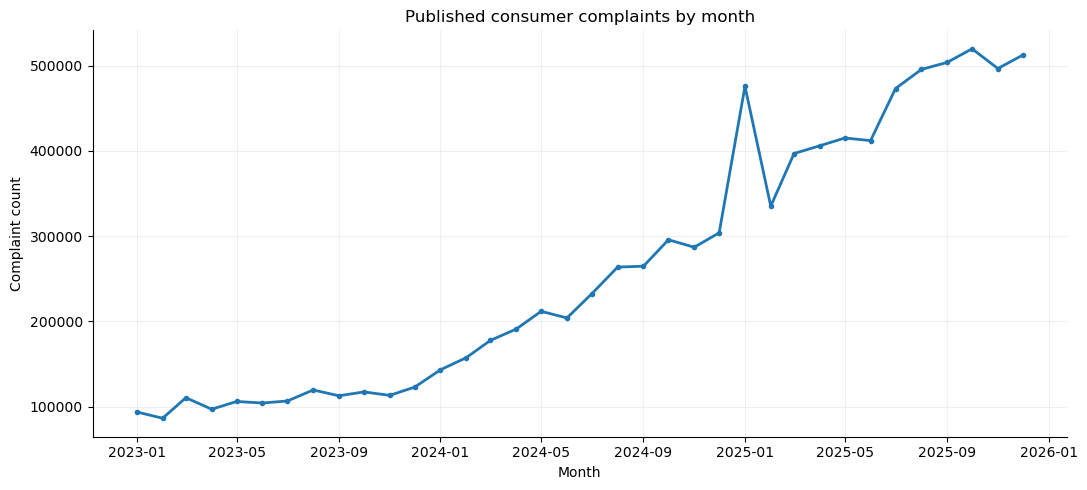

In [5]:
annual = work.groupby("year").size().rename("complaints").reset_index()
annual["yoy_pct"] = annual["complaints"].pct_change() * 100
monthly = work.groupby("month").size().rename("complaints").reset_index()
monthly["month_date"] = pd.to_datetime(monthly["month"])
display(annual.style.format({"complaints":"{:,.0f}", "yoy_pct":"{:+.1f}%"}, na_rep="—"))
fig, ax = plt.subplots()
ax.plot(monthly["month_date"], monthly["complaints"], linewidth=2, marker=".")
ax.set(title="Published consumer complaints by month", xlabel="Month", ylabel="Complaint count")
ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(OUT/"01_monthly_trend.png", dpi=170); plt.show()

## 6 · Product concentration and issue analysis

The first chart identifies the largest product categories by **share of complaint records**. The second identifies issues by frequency. Both are descriptive and are not normalized by number of accounts or customers.

,product,complaints,share_pct
0,Credit reporting or other personal consumer re...,7577931,80.026712
1,"Credit reporting, credit repair services, or o...",644814,6.809556
2,Debt collection,507203,5.356315
3,Credit card,187839,1.983673
4,Checking or savings account,186889,1.973641
5,"Money transfer, virtual currency, or money ser...",115119,1.215714
6,Mortgage,68988,0.728548
7,Vehicle loan or lease,46922,0.495520
8,Student loan,46571,0.491813
9,Credit card or prepaid card,35310,0.372891


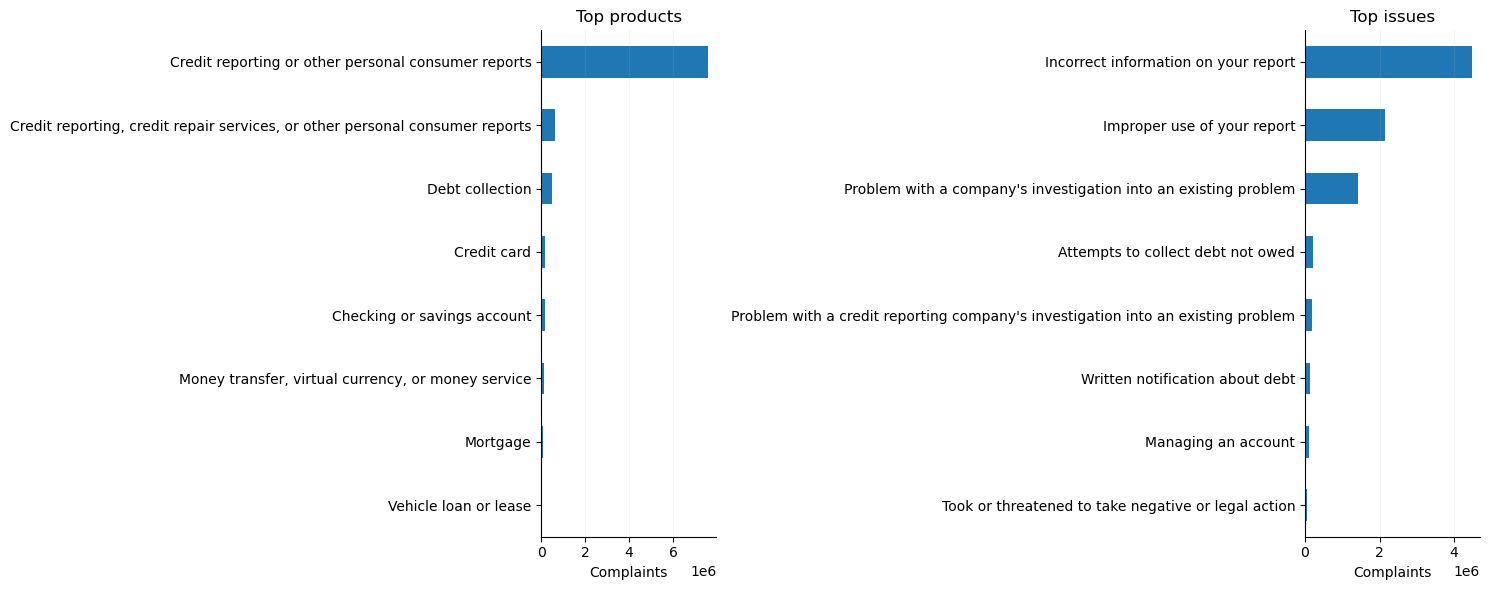

In [6]:
products = work.groupby("product").size().sort_values(ascending=False).rename("complaints").reset_index()
products["share_pct"] = products["complaints"] / len(work) * 100
issues = work.groupby("issue").size().sort_values(ascending=False).rename("complaints").reset_index()
display(products.head(14))
fig, axes = plt.subplots(1,2,figsize=(15,6))
products.head(8).iloc[::-1].plot.barh(x="product",y="complaints",legend=False,ax=axes[0],title="Top products")
issues.head(8).iloc[::-1].plot.barh(x="issue",y="complaints",legend=False,ax=axes[1],title="Top issues")
for ax in axes: ax.set(xlabel="Complaints",ylabel=""); ax.grid(axis="x",alpha=.15)
plt.tight_layout(); plt.savefig(OUT/"02_product_issue_mix.png",dpi=170,bbox_inches="tight"); plt.show()

## 7 · Response timeliness and response categories

A company with only a few complaints should not be compared uncritically to one with millions. We show company timeliness only above a **minimum 1,000 published complaints** threshold, which improves stability but does not solve market-share bias.

,response,complaints
0,Closed with explanation,5261466
1,Closed with non-monetary relief,4125656
2,Closed with monetary relief,70226
3,Untimely response,11610
4,In progress,275
5,Unknown,19


,company,complaints,timely_rate_pct
1665,"EQUIFAX, INC.",2762440,100.00
4564,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",2735218,100.00
1775,Experian Information Solutions Inc.,2450540,100.00
836,CAPITAL ONE FINANCIAL CORPORATION,71613,99.99
2516,JPMORGAN CHASE & CO.,59306,100.00
4971,WELLS FARGO & COMPANY,55371,100.00
744,"Block, Inc.",54591,98.42
598,"BANK OF AMERICA, NATIONAL ASSOCIATION",47806,98.21
895,"CITIBANK, N.A.",44224,100.00
4014,Resurgent Capital Services L.P.,42042,100.00


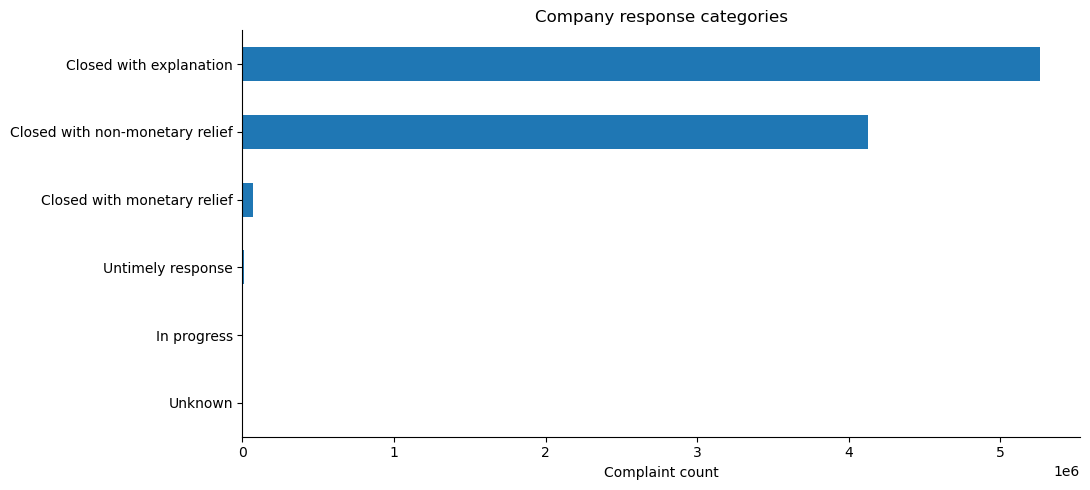

In [7]:
responses = work.groupby("response").size().sort_values(ascending=False).rename("complaints").reset_index()
company = work.groupby("company").agg(complaints=("complaint_id","size"),
        timely_rate=("timely_flag","mean")).reset_index()
company["timely_rate_pct"] = 100 * company["timely_rate"]
company_eligible = company.loc[company["complaints"]>=1000].copy()
company_top = company_eligible.sort_values("complaints",ascending=False).head(15)
display(responses)
display(company_top[["company","complaints","timely_rate_pct"]].round(2))
fig,ax=plt.subplots()
responses.iloc[::-1].plot.barh(x="response",y="complaints",legend=False,ax=ax)
ax.set(title="Company response categories",xlabel="Complaint count",ylabel="")
plt.tight_layout();plt.savefig(OUT/"03_response_categories.png",dpi=170,bbox_inches="tight");plt.show()

## 8 · Emerging issue monitor (descriptive signal)

For each **product × issue** pair, compare the final three months of 2025 with the preceding three months. Require **≥ 100 complaints in the baseline** to reduce unstable percentage spikes. This is an **early-warning screening rule**, not statistical proof of an emerging operational problem. Results can be distorted by seasonality, reporting changes, and category definitions.

In [8]:
recent_start, recent_end = "2025-10", "2025-12"
base_start, base_end = "2025-07", "2025-09"
base = work.loc[work["month"].between(base_start,base_end)].groupby(["product","issue"]).size().rename("baseline")
recent = work.loc[work["month"].between(recent_start,recent_end)].groupby(["product","issue"]).size().rename("recent")
risk = pd.concat([base,recent],axis=1).fillna(0).reset_index()
risk[["baseline","recent"]] = risk[["baseline","recent"]].astype(int)
risk["change"] = risk["recent"] - risk["baseline"]
risk["growth_pct"] = np.where(risk["baseline"]>0,100*risk["change"]/risk["baseline"],np.nan)
risk_signal = risk.query("baseline >= 100 and change > 0").sort_values(["growth_pct","change"],ascending=False)
display(risk_signal.head(15).round(1))

,product,issue,baseline,recent,change,growth_pct
39,Debt collection,Took or threatened to take negative or legal a...,11969,24056,12087,101.0
55,"Money transfer, virtual currency, or money ser...",Other transaction problem,1535,2847,1312,85.5
126,Vehicle loan or lease,Problem with a company's investigation into an...,126,189,63,50.0
61,"Money transfer, virtual currency, or money ser...",Unexpected or other fees,123,165,42,34.1
117,Student loan,Problem with a company's investigation into an...,162,213,51,31.5
67,Mortgage,Incorrect information on your report,186,229,43,23.1
60,"Money transfer, virtual currency, or money ser...",Unauthorized transactions or other transaction...,1178,1442,264,22.4
124,Vehicle loan or lease,Incorrect information on your report,418,508,90,21.5
52,"Money transfer, virtual currency, or money ser...","Managing, opening, or closing your mobile wall...",467,549,82,17.6
88,"Payday loan, title loan, personal loan, or adv...",Problem when making payments,437,507,70,16.0


## 9 · Geographic analysis

State figures represent counts of complaints with a recorded state. `Unknown` is excluded from the top-state chart, but the unknown-state count is reported. No per-capita or customer-base comparisons are implied.

Complaints without a reported state: 17,967


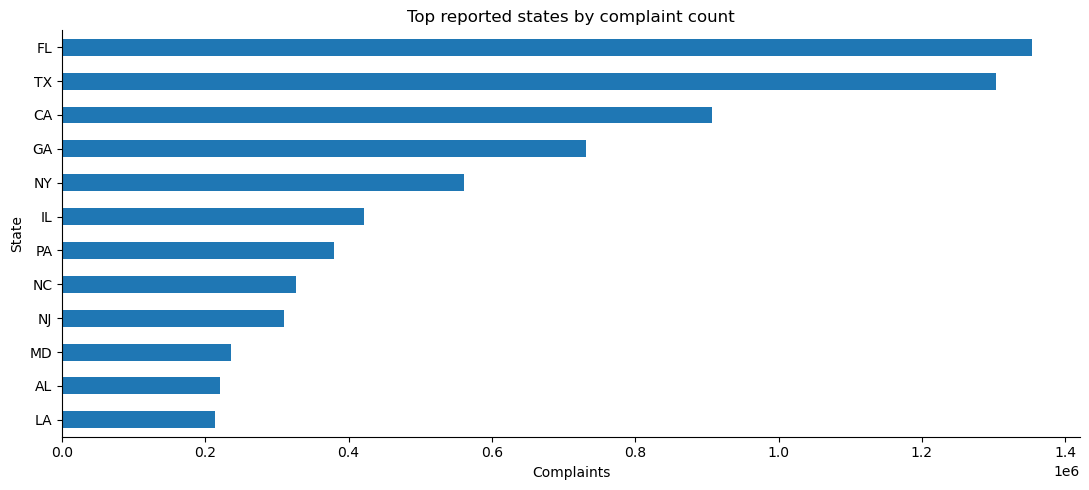

In [9]:
states = work.groupby("state").size().sort_values(ascending=False).rename("complaints").reset_index()
unknown_states = int(states.loc[states["state"].eq("Unknown"),"complaints"].sum())
state_known = states.loc[states["state"].ne("Unknown")]
print("Complaints without a reported state:",f"{unknown_states:,}")
fig,ax=plt.subplots()
state_known.head(12).iloc[::-1].plot.barh(x="state",y="complaints",legend=False,ax=ax)
ax.set(title="Top reported states by complaint count",xlabel="Complaints",ylabel="State")
plt.tight_layout();plt.savefig(OUT/"04_states.png",dpi=170);plt.show()

## 10 · SQL case study: aggregations, CTEs and window functions

SQLite is part of the Python standard library. To keep the notebook responsive on large datasets, we store a **monthly product aggregate** and a **company summary** rather than loading millions of raw rows into SQLite. SQL is used for reporting, not as a substitute for the original source. SQL queries below demonstrate `GROUP BY`, a `CTE`, `LAG()`, and `RANK()`.

In [10]:
product_month = work.groupby(["month","product"]).size().rename("complaints").reset_index()
con = sqlite3.connect(OUT/"banking_intelligence.db")
product_month.to_sql("product_month",con,if_exists="replace",index=False)
company[["company","complaints","timely_rate_pct"]].to_sql("company_summary",con,if_exists="replace",index=False)
annual.to_sql("annual_summary",con,if_exists="replace",index=False)
sql_trend = """
WITH monthly_totals AS (
 SELECT month, SUM(complaints) AS complaints
 FROM product_month GROUP BY month
), comparison AS (
 SELECT month, complaints,
        LAG(complaints) OVER (ORDER BY month) AS prior_month
 FROM monthly_totals
)
SELECT month, complaints, prior_month,
 ROUND(100.0*(complaints-prior_month)/NULLIF(prior_month,0),2) AS mom_pct
FROM comparison ORDER BY month;
"""
sql_rank = """
WITH ranked AS (
 SELECT company, complaints, ROUND(timely_rate_pct,2) AS timely_pct,
 RANK() OVER (ORDER BY complaints DESC) AS volume_rank
 FROM company_summary WHERE complaints >= 1000
)
SELECT * FROM ranked WHERE volume_rank <= 15 ORDER BY volume_rank;
"""
display(pd.read_sql_query(sql_trend,con).tail(12))
display(pd.read_sql_query(sql_rank,con))
(OUT/"analysis.sql").write_text(sql_trend+"\n-- Company ranking\n"+sql_rank,encoding="utf-8")
con.close()

,month,complaints,prior_month,mom_pct
24,2025-01,475783,303981.0,56.52
25,2025-02,335236,475783.0,-29.54
26,2025-03,396973,335236.0,18.42
27,2025-04,406099,396973.0,2.30
28,2025-05,415181,406099.0,2.24
29,2025-06,412160,415181.0,-0.73
30,2025-07,473181,412160.0,14.81
31,2025-08,495567,473181.0,4.73
32,2025-09,503847,495567.0,1.67
33,2025-10,519781,503847.0,3.16


,company,complaints,timely_pct,volume_rank
0,"EQUIFAX, INC.",2762440,100.00,1
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",2735218,100.00,2
2,Experian Information Solutions Inc.,2450540,100.00,3
3,CAPITAL ONE FINANCIAL CORPORATION,71613,99.99,4
4,JPMORGAN CHASE & CO.,59306,100.00,5
5,WELLS FARGO & COMPANY,55371,100.00,6
6,"Block, Inc.",54591,98.42,7
7,"BANK OF AMERICA, NATIONAL ASSOCIATION",47806,98.21,8
8,"CITIBANK, N.A.",44224,100.00,9
9,Resurgent Capital Services L.P.,42042,100.00,10


## 11 · Export reproducible analysis tables

Export nine aggregated CSV tables for reporting and independent review.

In [11]:
tables = {"annual_summary":annual, "monthly_summary":monthly,
          "product_summary":products, "issue_summary":issues,
          "response_summary":responses, "company_summary":company,
          "state_summary":states, "product_month":product_month,
          "emerging_issues":risk_signal}
for name, table in tables.items():
    table.to_csv(OUT/f"{name}.csv",index=False)
print("Exported",len(tables),"summary CSV tables to",OUT.resolve())

Exported 9 summary CSV tables to /Users/tsov/Desktop/project 1/Banking_Intelligence_360_GitHub_Ready/outputs


## 12 · Executive summary (generated from real results)

The narrative below is computed from the dataset at runtime, not invented. **Analyst interpretation:** changes in complaint counts are monitoring signals. Before recommending operational interventions, compare with internal volumes, customer counts, case-level outcomes and any taxonomy changes.

In [12]:
top_product = products.iloc[0]
last_year = annual.iloc[-1]
prior_year = annual.iloc[-2]
change = (last_year["complaints"]/prior_year["complaints"]-1)*100
signal = risk_signal.iloc[0] if len(risk_signal) else None
signal_text = (f"The leading screening signal was **{signal['product']} / {signal['issue']}**, "
               f"up **{signal['growth_pct']:.1f}%** across the compared three-month windows "
               f"({signal['baseline']:,} → {signal['recent']:,} complaints)." if signal is not None else
               "No product/issue pair met the defined baseline and growth thresholds.")
summary = f"""# Executive findings — 2023–2025

- **Coverage:** {len(work):,} published complaints from {work['company'].nunique():,} companies and {work['product'].nunique()} product categories.
- **2025 vs 2024:** {last_year['complaints']:,} versus {prior_year['complaints']:,} published complaints (**{change:+.1f}%**).
- **Largest product category:** {top_product['product']} ({top_product['complaints']:,}; **{top_product['share_pct']:.1f}%** of complaints).
- **Recorded timely responses:** **{100*work['timely_flag'].mean():.2f}%** (not a measure of resolution quality).
- **Emerging issue screen:** {signal_text}

**Management actions:** (1) validate high-growth issues against internal complaint logs and customer denominators; (2) investigate response outcomes for high-volume products; (3) monitor trends monthly, including taxonomy and reporting changes.

**Caveat:** CFPB complaint counts cannot establish customer experience rates, causal effects, or company misconduct. Published records are not representative of all consumers.
"""
display(Markdown(summary))
(OUT/"EXECUTIVE_SUMMARY.md").write_text(summary,encoding="utf-8")

# Executive findings — 2023–2025

- **Coverage:** 9,469,252 published complaints from 5,149 companies and 14 product categories.
- **2025 vs 2024:** 5,442,936.0 versus 2,734,268.0 published complaints (**+99.1%**).
- **Largest product category:** Credit reporting or other personal consumer reports (7,577,931; **80.0%** of complaints).
- **Recorded timely responses:** **99.60%** (not a measure of resolution quality).
- **Emerging issue screen:** The leading screening signal was **Debt collection / Took or threatened to take negative or legal action**, up **101.0%** across the compared three-month windows (11,969 → 24,056 complaints).

**Management actions:** (1) validate high-growth issues against internal complaint logs and customer denominators; (2) investigate response outcomes for high-volume products; (3) monitor trends monthly, including taxonomy and reporting changes.

**Caveat:** CFPB complaint counts cannot establish customer experience rates, causal effects, or company misconduct. Published records are not representative of all consumers.


1064